# Masking across signals: warp a mask from one signal onto another

Interactively register a mask made on one signal (here **EDX**: Cr and Zr maps) onto the pixel grid of another signal acquired from the same region (here **SEND / 4D-STEM**: azimuthal variance), then use it to select diffraction-derived data.

Each signal provides a 2-D *reference image* (EDX: total counts; STEM: azimuthal-mean sum). You click the **same features** in both; a transform is fitted to those pairs and applied to the mask.

1. Build masks on the EDX grid (the registration does not care how a mask was made)
2. Pick matching control points in the two reference images
3. Fit the transform and check the residuals and the overlay
4. Warp the masks onto the STEM grid. `warp_mask` also returns **where the EDX field of view actually covered the STEM grid**
5. Save the registration so it can be reproduced, and use the masks

Needs `%matplotlib widget` (ipympl) for the click interface.

## Assumptions

1. **Same region, nothing moved.** The two signals were acquired from the same physical region, and the specimen did not drift, shrink or change between them. For a beam-sensitive sample this is the assumption most likely to fail.
2. **The mapping is a similarity** (one uniform scale, a rotation and a translation): no mirroring, shear, different x/y scales or lens distortion. `transform_type='affine'` relaxes this (see Suggestions).
3. **The same features are recognisable in both reference images**, even if the contrast differs (it is often inverted between EDX and STEM).
4. **Masks and reference images share a pixel grid.** The EDX mask and the EDX reference image must have the same shape, binning and orientation, and the STEM reference image must have the same shape as the first two axes of the signal the mask will be applied to. Both are asserted below.
5. **Coordinates are (column, row) in the arrays as displayed** (`imshow`, origin at top-left, no transpose), with pixel centres at integer positions. Matplotlib and scikit-image use the same convention, so clicks need no conversion.
6. **Clicks are paired by order**: the n-th point in the first image matches the n-th point in the second.

## Limitations

1. **Pixels outside the source field of view carry no information.** Warping with a fill value of 0 labels them "not in the mask". If the source covers only part of the target grid, that is wrong. With the transform fitted in the original version of this notebook, about **14 %** of the STEM grid (columns >= ~223) lay outside the EDX footprint. `warp_mask` returns a `covered` array; use it to separate "EDX says no" from "EDX never looked".
2. **Two pairs always fit exactly.** A similarity has 4 parameters and 2 pairs supply 4 numbers, so the residual is zero whatever you clicked. The residuals only say something with 3 or more pairs (4 or more for `'affine'`). Points that are clustered or nearly co-linear make rotation and scale poorly determined, so spread them over the field.
3. **The mask edge cannot be sharper than the source pixel.** One EDX pixel covers `scale` STEM pixels (printed after fitting), and a click error of one source pixel moves the mask edge by about that much. STEM pixels near a mask boundary mix both phases.
4. **The warped mask is binary.** It comes from bilinear interpolation thresholded at 0.5; the soft values are returned as well.
5. **A similarity cannot represent a mirrored image.** If the two signals have opposite handedness (different scan or array conventions), residuals stay large however carefully you click.
6. **Interactive state is not saved by default.** Use `save_registration` / `load_registration` below, otherwise the result depends on clicks nobody recorded.
7. **Untested in a live frontend.** The click logic was tested with simulated mouse events; the ipympl widgets themselves (buttons, toolbar interaction) were not exercised outside Jupyter.

*Why manual control points?* Automatic registration (ORB features, segmentation plus centroid matching, mutual information) was tried on synthetic image pairs imitating this one (inverted contrast, shot-noise-limited EDX) and failed or silently gave a wrong answer, so the human picks the correspondence and the code does the rest.

In [1]:
%matplotlib widget
import json
import warnings

import h5py as h5
import hyperspy.api as hs
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from skimage.filters import threshold_otsu
from skimage.transform import AffineTransform, SimilarityTransform, estimate_transform, warp

## 1. Source signal: masks on the EDX grid

In [2]:
def make_mask(map2d, method='otsu', smooth_sigma=1.0, percentile=90,
              abs_threshold=None, min_size=4, close_iterations=1):
    """Boolean mask from a 2-D map. method: 'otsu', 'percentile' or 'absolute'.

    Objects smaller than `min_size` pixels are dropped and the mask is closed
    `close_iterations` times with a 3x3 element. Written with scipy.ndimage so it
    does not depend on scikit-image's morphology API (which is being renamed).
    """
    data = np.asarray(map2d, dtype=float)
    data_s = gaussian_filter(data, smooth_sigma) if smooth_sigma else data

    if method == 'otsu':
        thresh = threshold_otsu(data_s)
    elif method == 'percentile':
        thresh = np.percentile(data_s, percentile)
    elif method == 'absolute':
        if abs_threshold is None:
            raise ValueError("abs_threshold must be set for method='absolute'")
        thresh = abs_threshold
    else:
        raise ValueError(f'unknown method {method!r}')

    mask = data_s > thresh
    if min_size:
        labels, _ = ndi.label(mask)                      # 4-connected
        sizes = np.bincount(labels.ravel())
        keep = sizes >= min_size
        keep[0] = False
        mask = keep[labels]
    structure = np.ones((3, 3), bool)
    for _ in range(int(close_iterations or 0)):
        # closing as scikit-image defined it: dilate with an empty outside, then erode with the outside treated
        # as set, so features touching the image edge are not eaten (verified identical on 800 test masks)
        mask = ndi.binary_dilation(mask, structure=structure, border_value=0)
        mask = ndi.binary_erosion(mask, structure=structure, border_value=1)
    return mask, thresh

In [3]:
rpl_file = r'/dls/e02/data/2026/mg44469-1/EDX/EDX_data/exports_project1/Map Data 46-EDS Data 46.rpl'
h5oina_file = r'/dls/e02/data/2026/mg44469-1/EDX/EDX_data/Project 1/h5oina/Project 1 MIL101-Daphnia_Juveniles_48h_Depuration Site 2 Map Data 43.h5oina'
elements = ['Cl', 'C', 'F', 'N', 'O', 'P', 'S', 'Au', 'Cr', 'Zr']

In [4]:
edx = hs.load(rpl_file)
edx = edx.transpose()
edx.set_signal_type('EDS_TEM')
edx.axes_manager[0].name = 'x'
edx.axes_manager[1].name = 'y'
edx.axes_manager[2].name = 'Energy'

with h5.File(h5oina_file, 'r') as f:
    edx_channel_width = f['1']['EDS']['Header']['Channel Width'][()]
    edx_binning = f['1']['EDS']['Header']['Binning'][()]
    edx_x_step = f['1']['EDS']['Header']['X Step'][()] / edx_binning[0]
    edx_y_step = f['1']['EDS']['Header']['Y Step'][()] / edx_binning[0]
    ch_offset = f['1']['EDS']['Header']['Start Channel'][()]
    beam_voltage = f['1']['EDS']['Header']['Beam Voltage'][()]

edx.axes_manager['Energy'].scale = edx_channel_width[0] * 0.001
edx.axes_manager['Energy'].units = 'keV'
edx.axes_manager['Energy'].offset = ch_offset[0] * edx_channel_width[0] * 0.0001
edx.axes_manager['x'].scale = edx_x_step[0]
edx.axes_manager['y'].scale = edx_y_step[0]
edx.axes_manager['x'].units = 'um'
edx.axes_manager['y'].units = 'um'
edx.metadata.Acquisition_instrument.TEM.beam_energy = beam_voltage

print(edx.axes_manager)
edx.add_elements(elements)

# bin 2x2 for signal-to-noise. The mask AND the reference image below both come from this binned
# signal, so they are on the same pixel grid (assumption 4).
edx_bin2 = edx.rebin(scale=(2, 2, 1))
edx_ref_img = edx_bin2.T.sum().data.astype(float)     # total counts per pixel: the EDX reference image

/dls_sw/apps/python/miniforge/25.11/envs/epsic3.13/lib/python3.13/site-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazyComplexSignal1D` from `hyperspy._signals.complex_signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(
/dls_sw/apps/python/miniforge/25.11/envs/epsic3.13/lib/python3.13/site-packages/hyperspy/misc/_utils.py:1590: VisibleDeprecationWarning: Importing `LazySignal1D` from `hyperspy._signals.signal1d` is deprecated and will be removed in the HyperSpy 3.0 release. Import it from `hyperspy.signals` instead.
  warnings.warn(


<Axes manager, axes: (512, 512|2048)>
            Name |   size |  index |  offset |   scale |  units 
================ | ====== | ====== | ======= | ======= | ====== 
               x |    512 |      0 |       0 |  0.0033 |     um 
               y |    512 |      0 |       0 |  0.0033 |     um 
---------------- | ------ | ------ | ------- | ------- | ------ 
          Energy |   2048 |      0 |    -0.2 |    0.01 |    keV 


In [5]:
maps = edx_bin2.get_lines_intensity()
for i in (3, -1):
    print(i, maps[i].metadata.General.title)            # confirm which line each index refers to

cr_mask_edx, cr_thresh = make_mask(maps[3].data, method='percentile', percentile=90)
zr_mask_edx, zr_thresh = make_mask(maps[-1].data, method='percentile', percentile=95)
print(f'Cr threshold = {cr_thresh:.4g}, masked fraction = {cr_mask_edx.mean():.2%}')
print(f'Zr threshold = {zr_thresh:.4g}, masked fraction = {zr_mask_edx.mean():.2%}')

3 X-ray line intensity of : Cr_Ka at 5.41 keV
-1 X-ray line intensity of : Zr_Ka at 15.78 keV
Cr threshold = 0.6686, masked fraction = 11.13%
Zr threshold = 0.1825, masked fraction = 5.34%


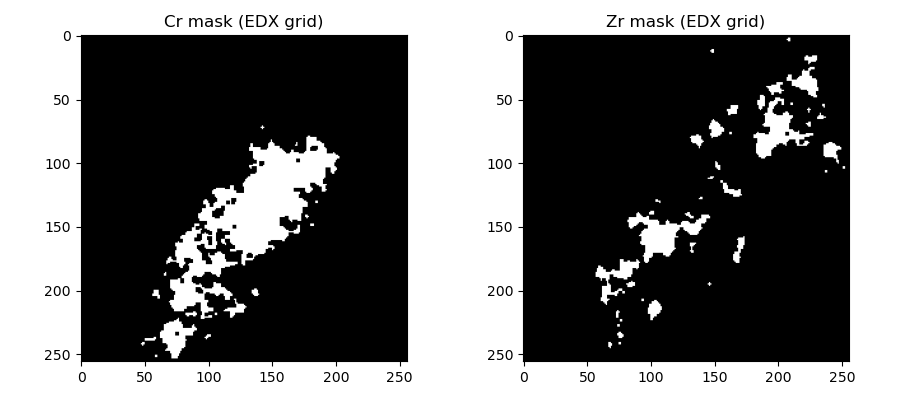

In [6]:
# every mask that will be warped with the same transform
edx_masks = {'Cr': cr_mask_edx, 'Zr': zr_mask_edx}
for name, m in edx_masks.items():
    assert m.shape == edx_ref_img.shape, (
        f'{name} mask {m.shape} is not on the same grid as the EDX reference image {edx_ref_img.shape}')

fig, axs = plt.subplots(1, len(edx_masks), figsize=(4.5 * len(edx_masks), 4), squeeze=False)
for ax, (name, m) in zip(axs[0], edx_masks.items()):
    ax.imshow(m, origin='upper', cmap='gray')
    ax.set_title(f'{name} mask (EDX grid)')
fig.tight_layout()

## 2. Target signal: STEM reference image and the signal to mask

In [7]:
var_file = '/dls/e02/data/2026/mg44469-1/processing/Merlin/MIL101_juveniles_48_hours_Depuration/20260910_174747/azim_var_outcomes/20260910_174747/20260910_174747_variance.hspy'
mean_file = '/dls/e02/data/2026/mg44469-1/processing/Merlin/MIL101_juveniles_48_hours_Depuration/20260910_174747/azim_var_outcomes/20260910_174747/20260910_174747_mean.hspy'
var_sig = hs.load(var_file)
mean_sig = hs.load(mean_file)

stem_shape = var_sig.data.shape[:2]                     # (rows, cols) of the scan; the mask must have exactly this shape
stem_ref_img = mean_sig.data.sum(axis=-1)               # ADF-like reference image: azimuthal mean summed over q
assert stem_ref_img.shape == stem_shape, (stem_ref_img.shape, stem_shape)
print(var_sig.axes_manager)

<Axes manager, axes: (255, 255|365)>
            Name |   size |  index |  offset |   scale |  units 
================ | ====== | ====== | ======= | ======= | ====== 
     <undefined> |    255 |      0 |       0 |       1 | <undefined> 
     <undefined> |    255 |      0 |       0 |       1 | <undefined> 
---------------- | ------ | ------ | ------- | ------- | ------ 
Scattering angle |    365 |      0 |       0 |  0.0054 |    1/A 


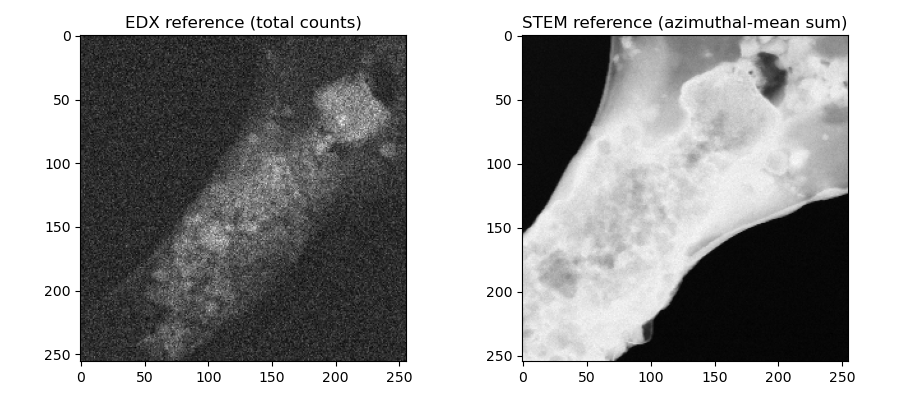

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
axs[0].imshow(edx_ref_img, origin='upper', cmap='gray')
axs[0].set_title('EDX reference (total counts)')
axs[1].imshow(np.sqrt(np.clip(stem_ref_img, 0, None)), origin='upper', cmap='gray')
axs[1].set_title('STEM reference (azimuthal-mean sum)')
fig.tight_layout()

## 3. Interactive registration

`ControlPointPicker` shows the two reference images and a live overlay (red = moving image warped onto the fixed grid, green = fixed image; yellow means aligned).

* **Left-click** a feature in one image, then the **same feature** in the other. Points are paired by click order, and the numbers on the markers show the pairing.
* **Right-click** (or the *Undo* buttons) removes the last point of that image.
* Clicks are ignored while the toolbar pan/zoom tool is active, so you can zoom in for precision. Switch the tool off before clicking.
* The fit refreshes whenever there are enough pairs. Watch the residuals (in source pixels) and the overlay.

Aim for **4-6 pairs spread over the whole field**, on features that are sharp in both images. An RMS residual of 1 source pixel or less is as good as the mask resolution allows.

In [9]:
def _percentile_stretch(img, lo=1, hi=99):
    vmin, vmax = np.percentile(img[np.isfinite(img)], [lo, hi])
    return vmin, vmax


def _norm01(img):
    img = np.nan_to_num(np.asarray(img, float))
    span = img.max() - img.min()
    return (img - img.min()) / span if span > 0 else np.zeros_like(img)


class ControlPointPicker:
    """Click matching features in two images and fit the transform that maps `moving` pixel
    coordinates onto `fixed` pixel coordinates.

    moving, fixed          2-D arrays. Points are (column, row) in these arrays as displayed.
    moving_display, fixed_display
                           optional arrays used only for display and the overlay (e.g. smoothed or
                           sqrt-scaled); they must have the same shape as the originals.
    transform_type         'similarity' (scale + rotation + translation, needs >= 2 pairs) or
                           'affine' (also mirror, shear, anisotropic scale, needs >= 3 pairs).
    """

    def __init__(self, moving, fixed, moving_display=None, fixed_display=None,
                 transform_type='similarity', moving_name='moving', fixed_name='fixed',
                 figsize=(15, 5)):
        if transform_type not in ('similarity', 'affine'):
            raise ValueError("transform_type must be 'similarity' or 'affine'")
        self.moving = np.nan_to_num(np.asarray(moving, float))
        self.fixed = np.asarray(fixed, float)
        self.moving_display = self.moving if moving_display is None else np.nan_to_num(np.asarray(moving_display, float))
        self.fixed_display = self.fixed if fixed_display is None else np.asarray(fixed_display, float)
        if self.moving_display.shape != self.moving.shape or self.fixed_display.shape != self.fixed.shape:
            raise ValueError('display images must have the same shape as the images they stand in for')
        self.transform_type = transform_type
        self.min_pairs = 2 if transform_type == 'similarity' else 3
        self.moving_name, self.fixed_name, self.figsize = moving_name, fixed_name, figsize
        self.moving_pts, self.fixed_pts = [], []
        self.tform = SimilarityTransform() if transform_type == 'similarity' else AffineTransform()
        self.fitted = False
        self.rms = None
        self.fig = None
        self._artists = []

    # ---- fitting -------------------------------------------------------------------------
    def fit(self):
        n_m, n_f = len(self.moving_pts), len(self.fixed_pts)
        n = min(n_m, n_f)
        lines = [f'{n_m} {self.moving_name} point(s), {n_f} {self.fixed_name} point(s)']
        if n_m != n_f:
            lines.append(f'{abs(n_m - n_f)} unpaired point(s) at the end are ignored: click the matching feature in the other image')
        self.fitted, self.rms = False, None
        if n < self.min_pairs:
            lines.append(f'need >= {self.min_pairs} matched pairs for a {self.transform_type} fit')
            self._report(lines)
            return None

        src, dst = np.array(self.moving_pts[:n]), np.array(self.fixed_pts[:n])
        tform = estimate_transform(self.transform_type, src, dst)
        params = getattr(tform, 'params', None)            # a failed estimate has no usable params
        if params is None or not np.all(np.isfinite(params)):
            lines.append('fit failed (points degenerate, e.g. identical or co-linear?): transform unchanged')
            self._report(lines)
            return None

        self.tform, self.fitted = tform, True
        resid = np.linalg.norm(tform(src) - dst, axis=1)
        det = np.linalg.det(params[:2, :2])
        ratio = np.sqrt(abs(det))                          # fixed px per moving px
        self.rms = float(np.sqrt(np.mean(resid ** 2)))
        if self.transform_type == 'similarity':
            lines.append(f'fit from {n} pairs: scale={ratio:.4g} {self.fixed_name} px per {self.moving_name} px, '
                         f'rotation={np.degrees(tform.rotation):.2f} deg, translation={tuple(np.round(tform.translation, 1))}')
        else:
            lines.append(f'fit from {n} pairs: mean scale={ratio:.4g}, det={det:.4g}'
                         + (' (MIRRORED)' if det < 0 else '') + f', translation={tuple(np.round(tform.translation, 1))}')
        lines.append(f'residual per pair ({self.fixed_name} px): {np.round(resid, 2)}; '
                     f'RMS = {self.rms:.2f} {self.fixed_name} px = {self.rms / ratio:.2f} {self.moving_name} px')
        if n == self.min_pairs:
            lines.append(f'NOTE: {n} pairs fit exactly, so these residuals say nothing about accuracy; add at least one more pair')
        elif self.rms / ratio > 1:
            lines.append(f'WARNING: RMS residual is more than one {self.moving_name} pixel: re-check the points'
                         + ("; if they are right, one image may be mirrored (try transform_type='affine')"
                            if self.transform_type == 'similarity' else ''))
        self._report(lines)
        return tform

    def warp(self, image, output_shape=None, order=1, cval=0.0, mode='constant'):
        """Resample an image on the moving grid onto the fixed grid."""
        return warp(image, self.tform.inverse, output_shape=output_shape or self.fixed.shape,
                    order=order, cval=cval, mode=mode)

    def set_points(self, moving_pts, fixed_pts):
        """Load points (e.g. from a saved registration) and refit."""
        self.moving_pts = [tuple(p) for p in moving_pts]
        self.fixed_pts = [tuple(p) for p in fixed_pts]
        self._after_change()

    # ---- interface -----------------------------------------------------------------------
    def show(self):
        self.fig, (self.ax_moving, self.ax_fixed, self.ax_overlay) = plt.subplots(1, 3, figsize=self.figsize)
        self.ax_moving.imshow(self.moving_display, cmap='gray', vmin=_percentile_stretch(self.moving_display)[0],
                              vmax=_percentile_stretch(self.moving_display)[1])
        self.ax_moving.set_title(f'{self.moving_name}: click a feature')
        self.ax_fixed.imshow(self.fixed_display, cmap='gray', vmin=_percentile_stretch(self.fixed_display)[0],
                             vmax=_percentile_stretch(self.fixed_display)[1])
        self.ax_fixed.set_title(f'{self.fixed_name}: click the SAME feature')
        self.ax_overlay.imshow(np.zeros(self.fixed.shape + (3,)))
        self.ax_overlay.set_title(f'overlay (red={self.moving_name}, green={self.fixed_name})')

        self.status = widgets.Output()
        reset = widgets.Button(description='Reset points')
        undo_m = widgets.Button(description=f'Undo {self.moving_name} point')
        undo_f = widgets.Button(description=f'Undo {self.fixed_name} point')
        reset.on_click(lambda _: self.reset())
        undo_m.on_click(lambda _: self.undo('moving'))
        undo_f.on_click(lambda _: self.undo('fixed'))
        display(widgets.HBox([reset, undo_m, undo_f]), self.status)
        self.fig.canvas.mpl_connect('button_press_event', self._onclick)
        self._after_change()

    def reset(self):
        self.moving_pts.clear()
        self.fixed_pts.clear()
        self._after_change()

    def undo(self, which):
        pts = self.moving_pts if which == 'moving' else self.fixed_pts
        if pts:
            pts.pop()
            self._after_change()

    def _onclick(self, event):
        toolbar = getattr(self.fig.canvas, 'toolbar', None)
        mode = getattr(toolbar, 'mode', '')
        mode = getattr(mode, 'value', mode)
        if mode:                                           # pan/zoom tool active: this click is navigation
            return
        if event.inaxes is self.ax_moving:
            which = 'moving'
        elif event.inaxes is self.ax_fixed:
            which = 'fixed'
        else:
            return
        if event.button == 1 and event.xdata is not None:
            (self.moving_pts if which == 'moving' else self.fixed_pts).append((event.xdata, event.ydata))
            self._after_change()
        elif event.button == 3:
            self.undo(which)

    def _after_change(self):
        self.fit()
        if self.fig is not None:
            self._redraw()

    def _redraw(self):
        for artist in self._artists:
            artist.remove()
        self._artists = []
        for ax, pts in ((self.ax_moving, self.moving_pts), (self.ax_fixed, self.fixed_pts)):
            for i, (x, y) in enumerate(pts):
                self._artists.append(ax.plot(x, y, 'o', color='lime', markersize=6)[0])
                self._artists.append(ax.annotate(str(i + 1), (x, y), color='yellow', fontsize=11,
                                                 xytext=(4, 4), textcoords='offset points'))
        warped = warp(_norm01(self.moving_display), self.tform.inverse, output_shape=self.fixed.shape,
                      order=1, cval=0.0) if self.fitted else np.zeros(self.fixed.shape)
        rgb = np.zeros(self.fixed.shape + (3,))
        rgb[..., 0] = warped
        rgb[..., 1] = _norm01(self.fixed_display)
        self.ax_overlay.images[0].set_data(rgb)
        self.fig.canvas.draw_idle()

    def _report(self, lines):
        if self.fig is None:
            print('\n'.join(lines))
            return
        with self.status:
            self.status.clear_output()
            print('\n'.join(lines))


def warp_mask(mask, tform, output_shape, threshold=0.5):
    """Warp a boolean mask on the source grid onto the target grid.

    Returns (mask_out, covered, soft):
      mask_out  boolean, True where the warped mask exceeds `threshold` AND the source covered the pixel
      covered   boolean, True where the target pixel falls inside the source image at all. Outside it the
                source has no information: that is NOT the same as "not in the mask".
      soft      the interpolated mask in [0, 1] (usable as weights)
    The border is replicated while interpolating so `soft` is not pulled towards 0 at the edge of the
    source image; `covered` is what marks the edge of the field of view.
    """
    inverse = tform.inverse
    soft = warp(np.asarray(mask, float), inverse, output_shape=output_shape, order=1, mode='edge')
    covered = warp(np.ones(np.shape(mask)), inverse, output_shape=output_shape, order=0, cval=0.0) > 0.5
    return (soft > threshold) & covered, covered, soft


def save_registration(path, picker, **meta):
    """Write the transform and the control points to JSON (plus any `meta`, e.g. the source file paths)."""
    info = dict(transform_type=picker.transform_type, matrix=picker.tform.params.tolist(),
                moving_points=picker.moving_pts, fixed_points=picker.fixed_pts,
                moving_shape=list(picker.moving.shape), fixed_shape=list(picker.fixed.shape),
                rms_fixed_px=picker.rms, meta=meta)
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(info, f, indent=2)


def load_registration(path, moving_shape=None, fixed_shape=None):
    """Read a saved registration. Returns (transform, info); warns if the image shapes differ."""
    with open(path, encoding='utf-8') as f:
        info = json.load(f)
    cls = AffineTransform if info['transform_type'] == 'affine' else SimilarityTransform
    for name, saved, now in (('moving', info['moving_shape'], moving_shape), ('fixed', info['fixed_shape'], fixed_shape)):
        if now is not None and list(now) != list(saved):
            warnings.warn(f'{name} image shape {tuple(now)} differs from the one registered ({tuple(saved)}); '
                          'this transform probably does not apply')
    return cls(matrix=np.array(info['matrix'])), info

Output()

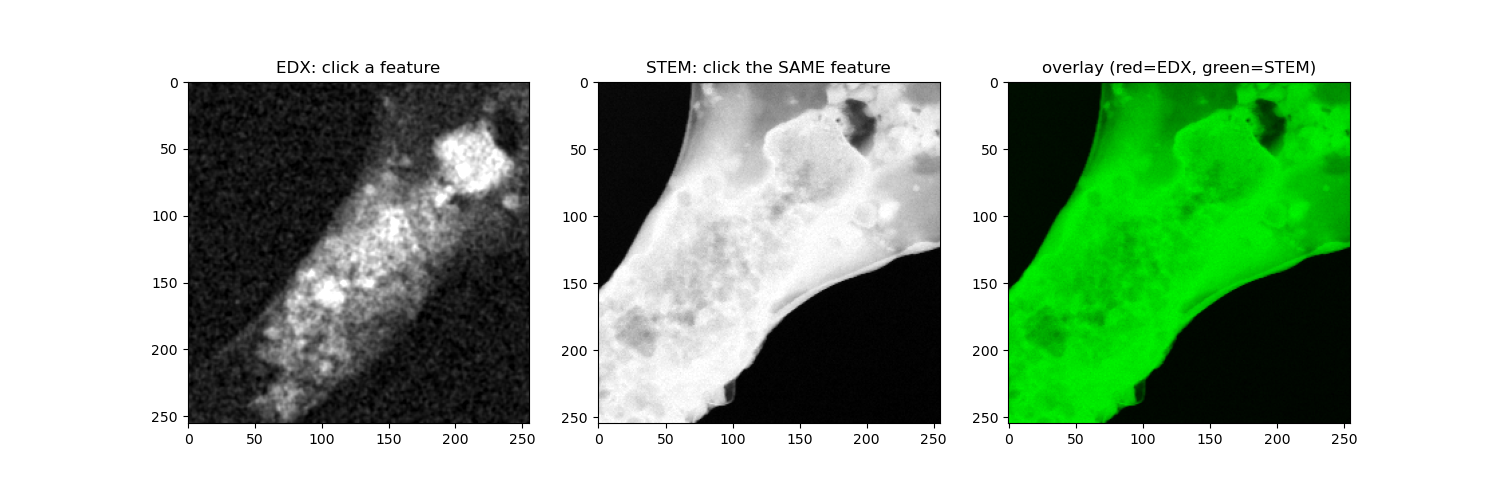

In [10]:
picker = ControlPointPicker(
    moving=edx_ref_img,
    fixed=stem_ref_img,
    moving_display=gaussian_filter(edx_ref_img, 1.0),            # display only: makes shot-noise-limited EDX easier to click
    fixed_display=np.sqrt(np.clip(stem_ref_img, 0, None)),       # display only
    transform_type='similarity',                                 # 'affine' if one image may be mirrored or sheared
    moving_name='EDX', fixed_name='STEM',
)
picker.show()

## 4. Apply the transform to the masks

Everything below uses `picker.tform`, so run it after the points are picked. Re-run it if you change a point.

Cr: 11.13% of the EDX map -> 15.51% of the STEM grid (17.93% of the part of it the EDX covers)
Zr: 5.34% of the EDX map -> 7.62% of the STEM grid (8.80% of the part of it the EDX covers)
EDX covers 86.5% of the STEM grid; the other 13.5% has no EDX data


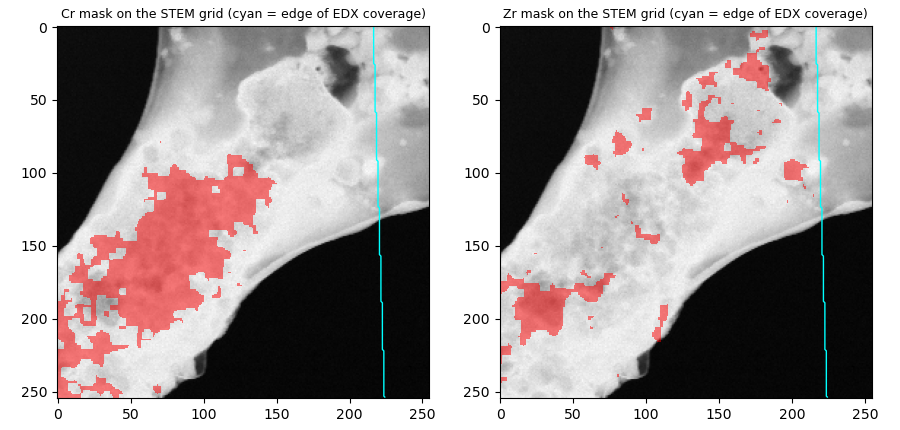

In [11]:
assert picker.fitted, 'pick at least %d matched pairs first' % picker.min_pairs
edx_to_stem_tform = picker.tform

stem_masks, stem_covered = {}, None
for name, m in edx_masks.items():
    stem_masks[name], stem_covered, _ = warp_mask(m, edx_to_stem_tform, stem_shape)
    in_view = stem_masks[name][stem_covered].mean()
    print(f'{name}: {m.mean():.2%} of the EDX map -> {stem_masks[name].mean():.2%} of the STEM grid '
          f'({in_view:.2%} of the part of it the EDX covers)')
print(f'EDX covers {stem_covered.mean():.1%} of the STEM grid; the other {1 - stem_covered.mean():.1%} has no EDX data')

stem_disp = np.sqrt(np.clip(stem_ref_img, 0, None))
fig, axs = plt.subplots(1, len(stem_masks), figsize=(4.5 * len(stem_masks), 4.3), squeeze=False)
for ax, (name, sm) in zip(axs[0], stem_masks.items()):
    ax.imshow(stem_disp, origin='upper', cmap='gray')
    ax.imshow(np.ma.masked_where(~sm, sm), origin='upper', cmap='autumn', alpha=0.5)
    ax.contour(stem_covered, levels=[0.5], colors='cyan', linewidths=1)
    ax.set_title(f'{name} mask on the STEM grid (cyan = edge of EDX coverage)', fontsize=9)
fig.tight_layout()

In [12]:
# keep a record of how this mask was made
save_registration('registration_edx_to_stem.json', picker,
                  edx_rpl=rpl_file, edx_h5oina=h5oina_file, stem_variance=var_file, stem_mean=mean_file)
# later, or in another notebook:
# edx_to_stem_tform, info = load_registration('registration_edx_to_stem.json',
#                                             moving_shape=edx_ref_img.shape, fixed_shape=stem_shape)

## 5. Using the masks

Three populations, not two: **in the mask**, **outside the mask but covered by the EDX**, and **not covered**. Only the first two can be compared.

Cr: 10084 px inside, 46168 px outside, 8773 px with no EDX data (excluded)


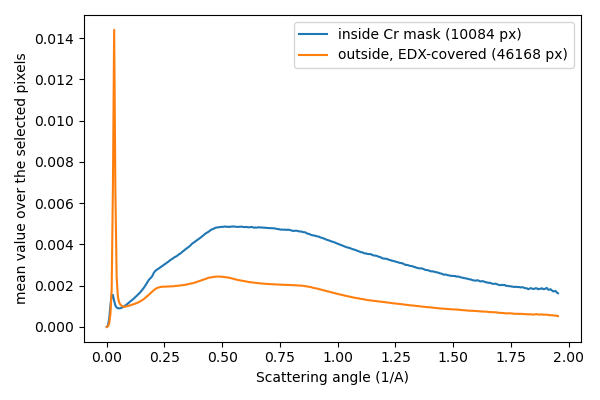

In [13]:
name = 'Cr'
inside = stem_masks[name]
outside = stem_covered & ~inside                  # EDX looked here and found no Cr
no_data = ~stem_covered
print(f'{name}: {inside.sum()} px inside, {outside.sum()} px outside, {no_data.sum()} px with no EDX data (excluded)')

q_axis = var_sig.axes_manager.signal_axes[0].axis
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(q_axis, var_sig.data[inside].mean(axis=0), label=f'inside {name} mask ({inside.sum()} px)')
ax.plot(q_axis, var_sig.data[outside].mean(axis=0), label=f'outside, EDX-covered ({outside.sum()} px)')
ax.set_xlabel(f'{var_sig.axes_manager.signal_axes[0].name} ({var_sig.axes_manager.signal_axes[0].units})')
ax.set_ylabel('mean value over the selected pixels')
ax.legend()
fig.tight_layout()

## Suggestions

**Getting a better registration**
* Use **4-6 pairs spread over the whole field**, on sharp features visible in both images, and judge the fit by the RMS residual in *source* pixels (about 1 or less).
* Do a **hold-out check**: after fitting, look at one feature you did *not* click (a particle, a hole, a contamination spot) in the overlay. If it lands correctly the transform is trustworthy, not just consistent with its own points.
* If residuals stay large with well-placed points, try `transform_type='affine'` (needs 3 or more pairs). A negative determinant in the printout means the images are mirrored.
* The EDX total-counts image is shot-noise limited with the opposite contrast to the STEM image. The h5oina also stores an electron (HAADF/BSE) image on the EDX scan (`1/Electron Image/Data/BSE/...`, a flat array to reshape with the header's `Y Cells`/`X Cells`). It has the same contrast as the STEM reference and is far less noisy, so it is probably easier to click. It sits on a different grid from the EDS maps (512 x 512 against 256 x 256 in the example file I looked at), so you would compose the picked transform with that scale relation before warping the masks. I have not tried this on your data.

**Using the masks**
* **Exclude pixels with no EDX data** from any "outside the mask" population (`covered` above). If you need them, acquire EDX over a larger field than the STEM scan.
* Pixels at a mask boundary mix both phases. Erode the warped mask by about one source pixel (`scale` STEM pixels) before averaging, or use the soft values from `warp_mask` as weights.
* Check that a result does not depend on the registration: re-pick the points once and see whether the in/out profiles change by more than their noise.

**Reproducibility**
* Save the registration JSON next to the results (done above) and keep the reference images' source files in its `meta`.
* The same transform can be reused for a **second source mask** of the same region (the Zr mask here), or for another STEM signal on the same scan grid. It is not valid for a different scan or a different EDX map.

**Beyond a single global transform**
* If the scans differ by more than a similarity (scan-coil distortion, drift during a long EDX map), a global fit leaves position-dependent residuals. Check the residual *pattern* (are they all pointing the same way, or growing towards one edge?) and, if so, consider a piecewise-affine or polynomial warp with many more control points.